<a href="https://colab.research.google.com/github/nasiddiq69/Capstone-Company-Project/blob/main/demo_AI_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Thu Nov  5 04:39:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
!pip install -q "torchvision" "hydra-core" "iopath" "tqdm" "opencv-python" "matplotlib"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4


In [5]:
!git clone https://github.com/facebookresearch/sam2.git
%cd sam2
!pip install -q -e .

Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 18.89 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done


In [6]:
import torch
import sam2

from sam2.build_sam import build_sam2_video_predictor

print("SAM 2 imported successfully!")
print("SAM 2 location:", sam2.__file__)
print("CUDA:", torch.cuda.is_available())

SAM 2 imported successfully!
SAM 2 location: /content/sam2/sam2/__init__.py
CUDA: True


In [7]:
%cd /content/sam2
!mkdir -p checkpoints
!wget -c -O checkpoints/sam2.1_hiera_tiny.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt

/content/sam2
--2026-11-05 04:46:59--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.249.182.39, 13.249.182.62, 13.249.182.33, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.249.182.39|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 156008466 (149M) [application/vnd.snesdev-page-table]
Saving to: ‘checkpoints/sam2.1_hiera_tiny.pt’

checkpoints/sam2.1_ 100%[===================>] 148.78M   210MB/s    in 0.7s    

2026-11-05 04:47:00 (210 MB/s) - ‘checkpoints/sam2.1_hiera_tiny.pt’ saved [156008466/156008466]



In [8]:
import torch
from sam2.build_sam import build_sam2_video_predictor

checkpoint = "checkpoints/sam2.1_hiera_tiny.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_t.yaml"

predictor = build_sam2_video_predictor(
    model_cfg,
    checkpoint,
    device="cuda"
)

print("SAM 2.1 Tiny loaded successfully!")
print("Device:", next(predictor.parameters()).device)
print("Parameters:", sum(p.numel() for p in predictor.parameters()))

SAM 2.1 Tiny loaded successfully!
Device: cuda:0
Parameters: 38962498


In [9]:
from datasets import load_dataset

dataset = load_dataset(
    "MedOtter/CardiacUDC",
    "full_video",
    split="train",
    streaming=True
)

print("Dataset connected!")

for row in dataset.take(1):
    print("Video ID:", row["video_id"])
    print("Frame index:", row["frame_index"])
    print("Total frames:", row["n_frames"])
    print("Has ground truth:", row["has_mask"])
    print("Dense annotation:", row["gt_dense"])
    print("Image size:", row["image"].size)
    print("Mask available:", row["mask"] is not None)

README.md:   0%|          | 0.00/10.6k [00:00<?, ?B/s]

Dataset connected!
Video ID: Site_G_100/patient1-4
Frame index: 0
Total frames: 94
Has ground truth: False
Dense annotation: False
Image size: (800, 600)
Mask available: False


In [10]:
from datasets import load_dataset

annotated = load_dataset(
    "MedOtter/CardiacUDC",
    "annotated",
    split="train",
    streaming=True
)

selected = None

for row in annotated:
    if row["gt_dense"] and row["mask"] is not None:
        selected = row
        break

if selected is not None:
    print("Suitable video found!")
    print("Video ID:", selected["video_id"])
    print("Frame index:", selected["frame_index"])
    print("Total frames:", selected["n_frames"])
    print("Dense annotation:", selected["gt_dense"])
    print("Image size:", selected["image"].size)
    print("Mask size:", selected["mask"].size)
else:
    print("No densely annotated video found in this scan.")

Suitable video found!
Video ID: label_all_frame/normal-23-4
Frame index: 0
Total frames: 65
Dense annotation: True
Image size: (800, 600)
Mask size: (800, 600)


In [11]:
import os
import numpy as np
from PIL import Image
from datasets import load_dataset

video_id = "label_all_frame/normal-23-4"

annotated_data = load_dataset(
    "MedOtter/CardiacUDC",
    "annotated",
    split="train",
    streaming=True
)

rows = []

for row in annotated_data:
    if row["video_id"] == video_id:
        rows.append(row)

rows.sort(key=lambda x: x["frame_index"])

video_dir = "/content/echowave_demo/video_frames"
mask_dir = "/content/echowave_demo/ground_truth"

os.makedirs(video_dir, exist_ok=True)
os.makedirs(mask_dir, exist_ok=True)

for row in rows:
    idx = row["frame_index"]

    image = row["image"].convert("RGB")
    mask = row["mask"].convert("L")

    image.save(f"{video_dir}/{idx:05d}.jpg", quality=95)
    mask.save(f"{mask_dir}/{idx:05d}.png")

print("Video ID:", video_id)
print("Frames collected:", len(rows))
print("Expected frames:", rows[0]["n_frames"])
print("First frame:", rows[0]["frame_index"])
print("Last frame:", rows[-1]["frame_index"])
print("Mask labels:", np.unique(np.array(rows[0]["mask"])))
print("Video directory:", video_dir)

Video ID: label_all_frame/normal-23-4
Frames collected: 65
Expected frames: 65
First frame: 0
Last frame: 64
Mask labels: [0 1 2 3 4]
Video directory: /content/echowave_demo/video_frames


In [12]:
import numpy as np
import torch

# Initialize SAM 2 video processing
inference_state = predictor.init_state(
    video_path=video_dir,
    offload_video_to_cpu=True
)

# Load the ground-truth mask from the first frame
initial_mask = np.array(
    Image.open(f"{mask_dir}/00000.png")
)

print("Initial mask pixel counts:")

for class_id, class_name in {
    1: "LV",
    2: "LA",
    3: "RA",
    4: "RV"
}.items():

    binary_mask = initial_mask == class_id
    pixel_count = int(binary_mask.sum())

    print(f"{class_name}: {pixel_count} pixels")

    if pixel_count > 0:
        _, object_ids, mask_logits = predictor.add_new_mask(
            inference_state=inference_state,
            frame_idx=0,
            obj_id=class_id,
            mask=binary_mask
        )

print("\nInitial cardiac masks successfully provided to SAM 2!")
print("Tracked object IDs:", object_ids)

frame loading (JPEG): 100%|██████████| 65/65 [00:02<00:00, 26.20it/s]


Initial mask pixel counts:
LV: 17012 pixels
LA: 7691 pixels
RA: 5271 pixels
RV: 10995 pixels

Initial cardiac masks successfully provided to SAM 2!
Tracked object IDs: [1, 2, 3, 4]


/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7eefadf7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7eefadf076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7eefadf6f6a2 in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #3: 

In [13]:
import torch
import numpy as np

video_predictions = {}

with torch.inference_mode():
    for frame_idx, obj_ids, mask_logits in predictor.propagate_in_video(
        inference_state
    ):
        video_predictions[frame_idx] = {
            obj_id: (mask_logits[i] > 0).cpu().numpy().squeeze()
            for i, obj_id in enumerate(obj_ids)
        }

print("Propagation completed!")
print("Frames predicted:", len(video_predictions))
print("First frame:", min(video_predictions))
print("Last frame:", max(video_predictions))
print("Object IDs:", list(video_predictions[0].keys()))

propagate in video:   0%|          | 0/65 [00:00<?, ?it/s]/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7eefadf7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7eefadf076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7eefadf6f6a2 in /usr/local/li

Propagation completed!
Frames predicted: 65
First frame: 0
Last frame: 64
Object IDs: [1, 2, 3, 4]


In [14]:
import numpy as np
from PIL import Image

class_names = {1: "LV", 2: "LA", 3: "RA", 4: "RV"}

dice_scores = {class_id: [] for class_id in class_names}

for frame_idx in range(1, 65):  # Exclude frame 0: it was our input mask
    gt = np.array(
        Image.open(f"{mask_dir}/{frame_idx:05d}.png")
    )

    for class_id in class_names:
        pred = video_predictions[frame_idx][class_id].astype(bool)
        target = (gt == class_id)

        intersection = np.logical_and(pred, target).sum()
        denominator = pred.sum() + target.sum()

        dice = (
            2.0 * intersection / denominator
            if denominator > 0 else 1.0
        )

        dice_scores[class_id].append(dice)

print("SAM 2.1 Tiny — Forward propagation evaluation")
print("Evaluated frames: 1–64")
print()

for class_id, name in class_names.items():
    scores = dice_scores[class_id]
    print(f"{name}: Mean Dice = {np.mean(scores):.4f}")

all_scores = [
    score
    for scores in dice_scores.values()
    for score in scores
]

print()
print(f"Overall foreground mean Dice: {np.mean(all_scores):.4f}")

SAM 2.1 Tiny — Forward propagation evaluation
Evaluated frames: 1–64

LV: Mean Dice = 0.9068
LA: Mean Dice = 0.2343
RA: Mean Dice = 0.9084
RV: Mean Dice = 0.8207

Overall foreground mean Dice: 0.7176


In [15]:
import numpy as np
from PIL import Image

la_results = []

for frame_idx in range(1, 65):
    gt = np.array(
        Image.open(f"{mask_dir}/{frame_idx:05d}.png")
    )

    pred = video_predictions[frame_idx][2].astype(bool)
    target = (gt == 2)

    intersection = np.logical_and(pred, target).sum()
    dice = (
        2 * intersection / (pred.sum() + target.sum())
        if (pred.sum() + target.sum()) > 0 else 1.0
    )

    area_ratio = pred.sum() / max(target.sum(), 1)

    la_results.append((frame_idx, dice, area_ratio))

print("LA performance at selected frames:")
for frame_idx, dice, ratio in la_results:
    if frame_idx in [1, 8, 16, 24, 32, 40, 48, 56, 64]:
        print(
            f"Frame {frame_idx:02d}: "
            f"Dice={dice:.4f}, "
            f"Predicted/GT area={ratio:.2f}"
        )

print("\nLowest LA Dice frames:")
for frame_idx, dice, ratio in sorted(la_results, key=lambda x: x[1])[:5]:
    print(
        f"Frame {frame_idx:02d}: "
        f"Dice={dice:.4f}, "
        f"Area ratio={ratio:.2f}"
    )

LA performance at selected frames:
Frame 01: Dice=0.8778, Predicted/GT area=1.26
Frame 08: Dice=0.9178, Predicted/GT area=1.05
Frame 16: Dice=0.7994, Predicted/GT area=1.45
Frame 24: Dice=0.0000, Predicted/GT area=0.00
Frame 32: Dice=0.0000, Predicted/GT area=0.00
Frame 40: Dice=0.0000, Predicted/GT area=0.00
Frame 48: Dice=0.0000, Predicted/GT area=0.00
Frame 56: Dice=0.0000, Predicted/GT area=0.00
Frame 64: Dice=0.0000, Predicted/GT area=0.00

Lowest LA Dice frames:
Frame 18: Dice=0.0000, Area ratio=0.00
Frame 19: Dice=0.0000, Area ratio=0.00
Frame 20: Dice=0.0000, Area ratio=0.00
Frame 21: Dice=0.0000, Area ratio=0.00
Frame 22: Dice=0.0000, Area ratio=0.00


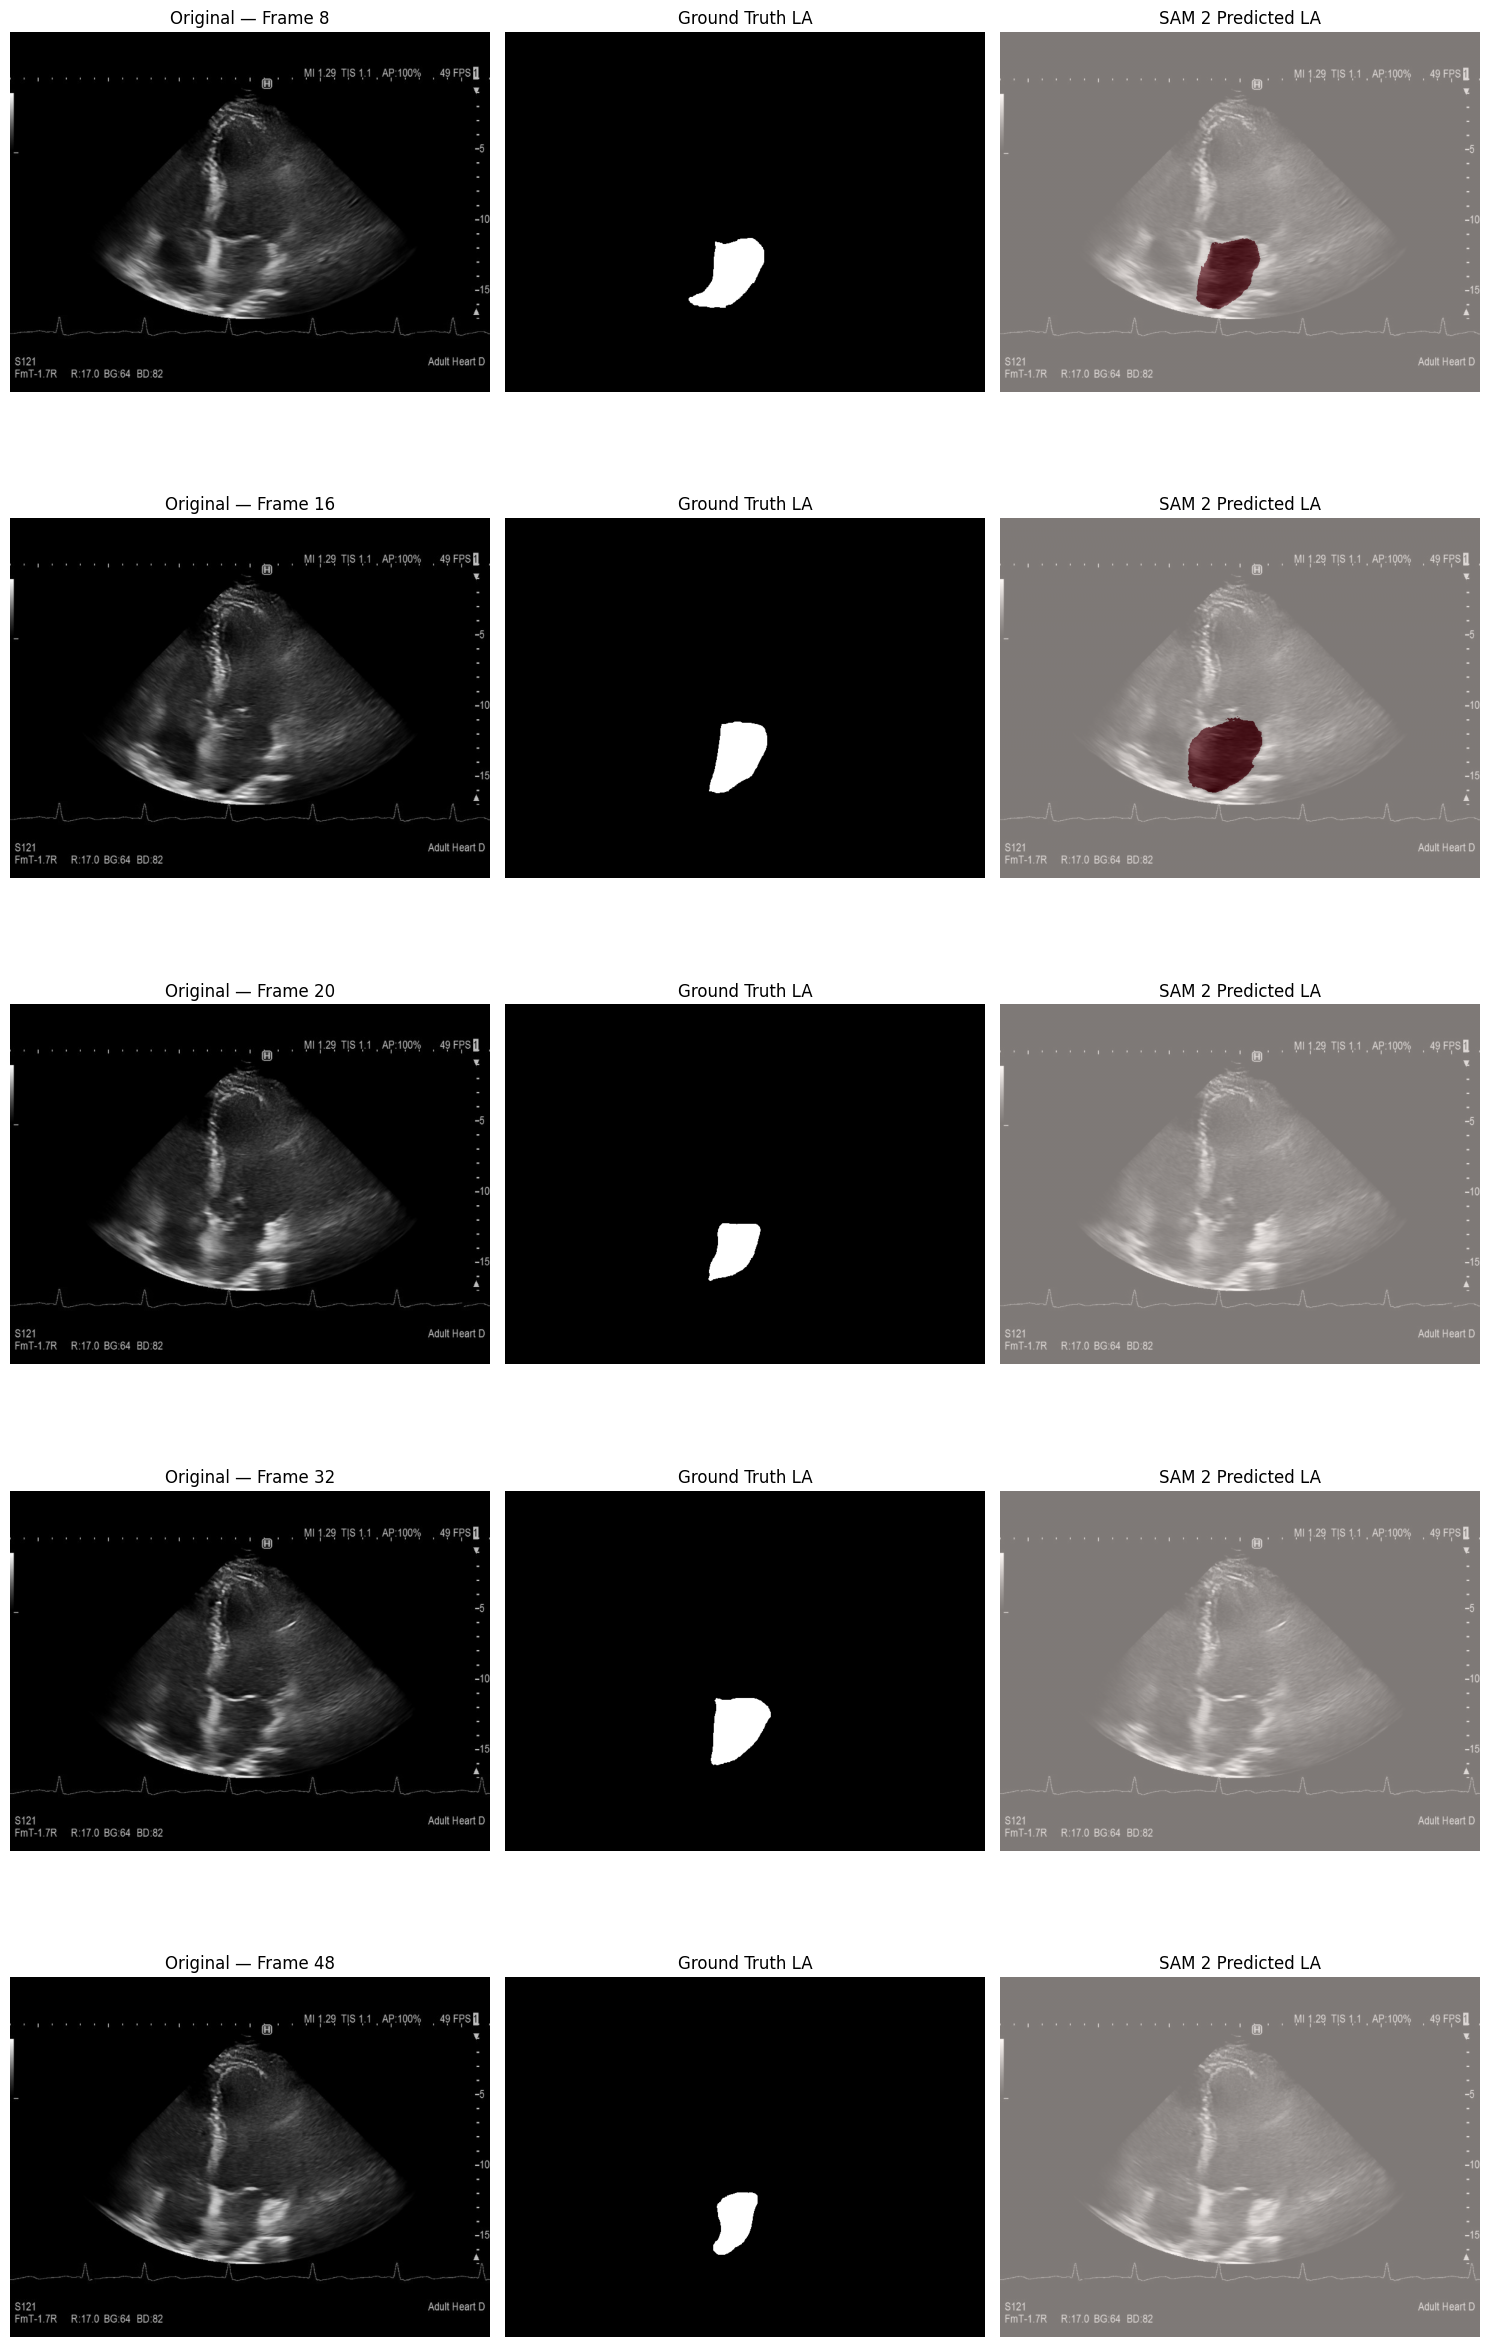

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

selected_frames = [8, 16, 20, 32, 48]

fig, axes = plt.subplots(
    len(selected_frames), 3,
    figsize=(15, 5 * len(selected_frames))
)

for row, frame_idx in enumerate(selected_frames):
    image = np.array(
        Image.open(f"{video_dir}/{frame_idx:05d}.jpg")
    )

    gt = np.array(
        Image.open(f"{mask_dir}/{frame_idx:05d}.png")
    )

    pred_la = video_predictions[frame_idx][2].astype(bool)

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"Original — Frame {frame_idx}")

    axes[row, 1].imshow(gt == 2, cmap="gray")
    axes[row, 1].set_title("Ground Truth LA")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(
        pred_la,
        cmap="Reds",
        alpha=0.5
    )
    axes[row, 2].set_title("SAM 2 Predicted LA")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()